In [1]:
# INICIALIZAÇÃO DAS BIBLIOTECAS
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
%matplotlib inline

def set_rho(ff):
    rho_fat = np.array(0.5)
    rho_water = np.array((rho_fat*((1-ff)/ff)))
    return(rho_fat,rho_water)

def discrete_timeseries(n_echoes):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T (TEs adjusted for 3T).
    This is based on studies by Hamilton and Yokoo.
    parameters: n_echoes     -> integer >0, number of equally spaced echoes
    returns:    echo_times
     '''
    
    #TE acquisition times for n echoes
    echo_times = np.linspace(0.0011515, 0.0011515*n_echoes, n_echoes, endpoint=True)
    
    return(echo_times)


def gen_GRE(echo_times, rho_fat, rho_water):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T (TEs adjusted for 3T).
    This is based on studies by Hamilton and Yokoo.
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
    returns:    Sabs (absolute signal intensity) (equivalent to ydata)
    '''
    rho = np.array([rho_fat*0.047,\
    rho_fat*0.039,\
    rho_fat*0.006,\
    rho_fat*0.12,\
    rho_fat*0.7,\
    rho_fat*0.088,\
    rho_water]) #rho_fat is a general variable that multiplies intrinsic fat constants (Hamilton)
    
    #standard, individual T2* values
    t2star = np.array([0.030,\
              0.040,\
              0.051,\
              0.052,\
              0.062,\
              0.083,\
              0.023] )
    
    #frequency in parts per million for each moiety
    freq_ppm = np.array([5.3,\
             4.2,\
             2.75,\
             2.1,\
             1.3,\
             0.9,\
             4.7])

    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0)      #magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.57e6) #Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    #calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         
    
    #obtain sum & absolute value
    Sabs= (len(echo_times))
    Sabs=np.zeros(Sabs,dtype='complex')
    
    Sabs = np.sum(S, axis=0)
    Sabs = np.absolute(Sabs)
    return(Sabs)


def continuous_timeseries(endpoint=0.01):
    return(np.linspace(0, endpoint, 1000, endpoint=True))

def calc_fatfrac(fitted_parameters):
    ff =  fitted_parameters[0] / (fitted_parameters[0] + fitted_parameters[1])
    return(ff)

## colocando erros não aleatórios nos valores iniciais

## variando o valor inicial da gordura

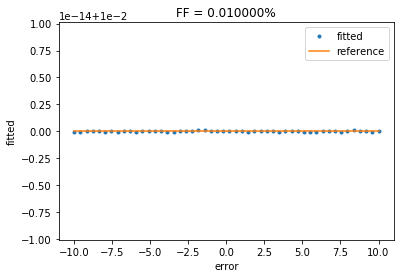

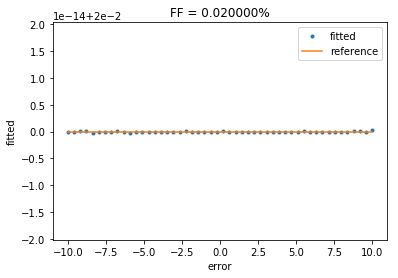

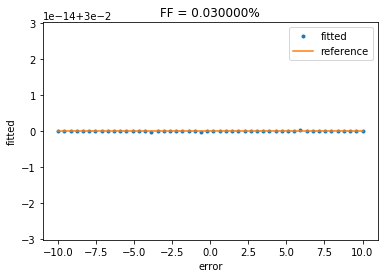

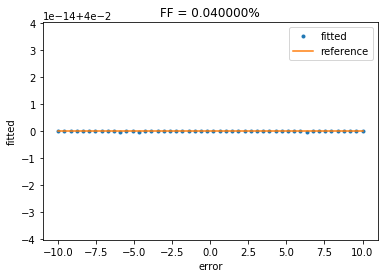

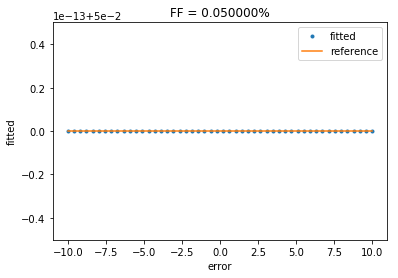

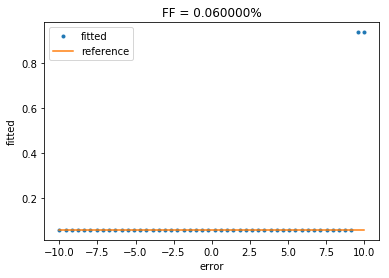

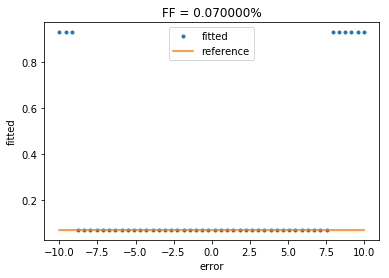

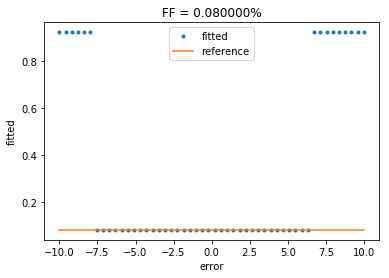

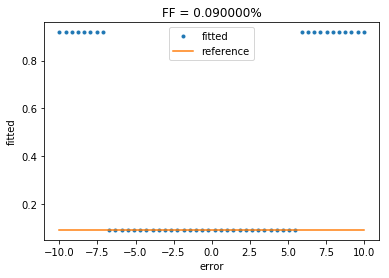

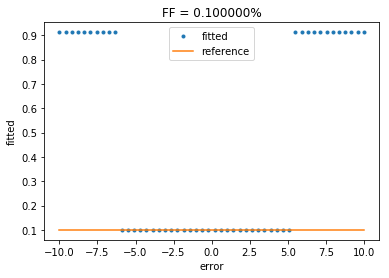

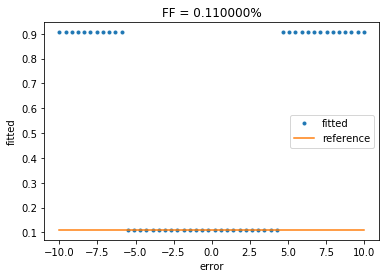

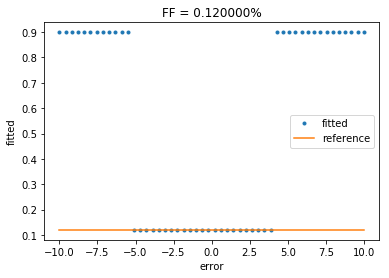

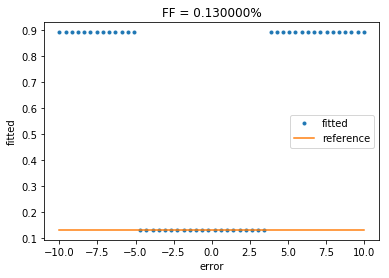

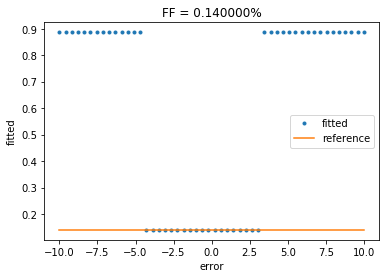

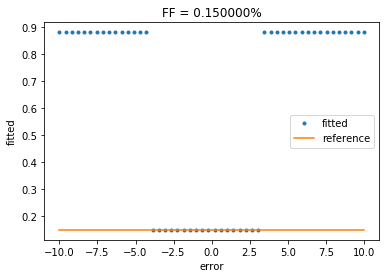

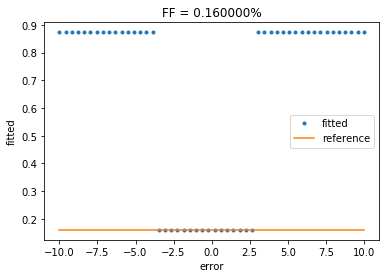

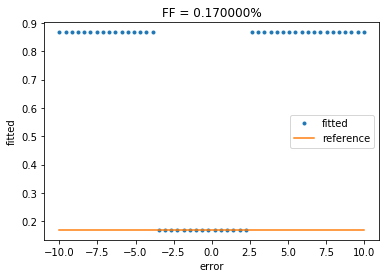

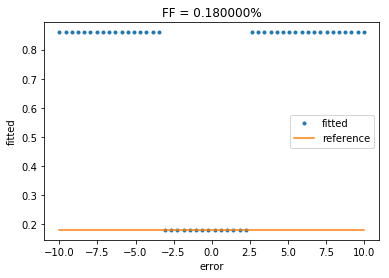

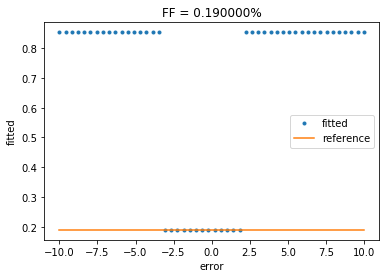

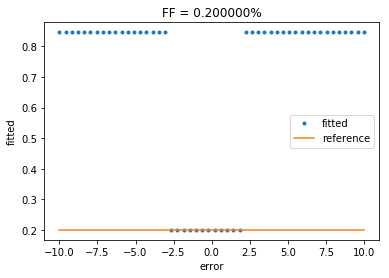

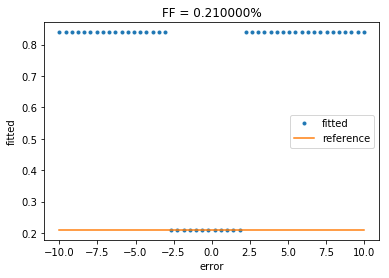

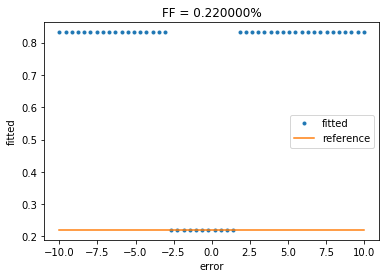

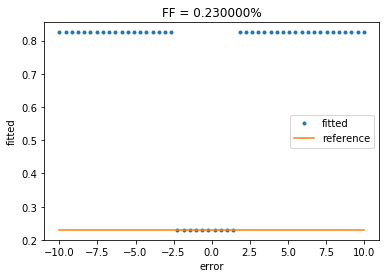

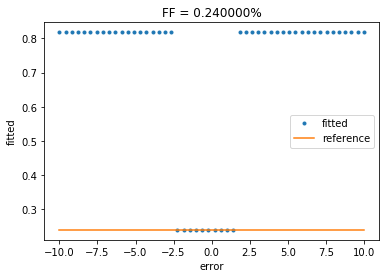

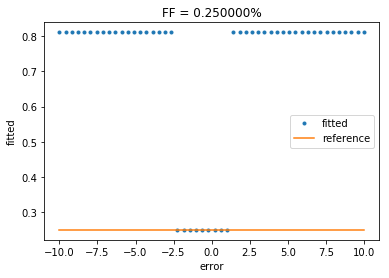

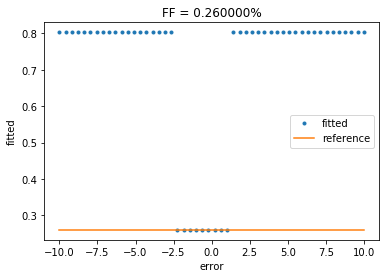

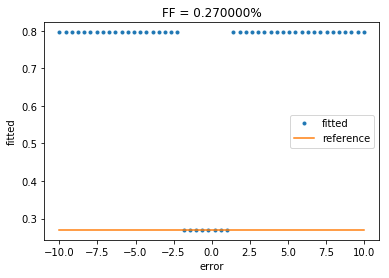

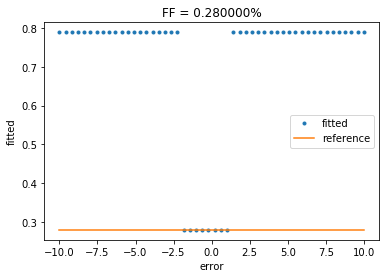

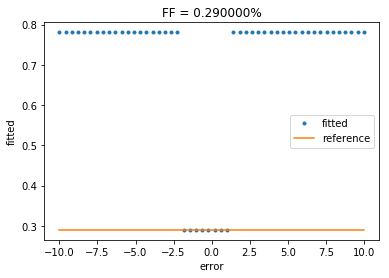

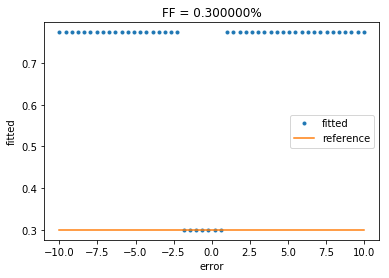

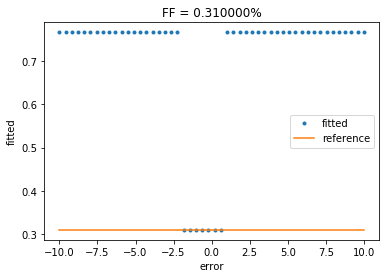

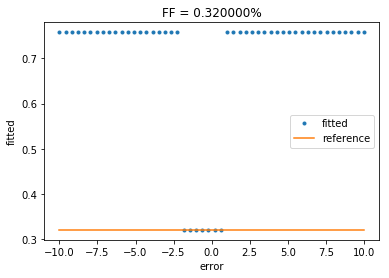

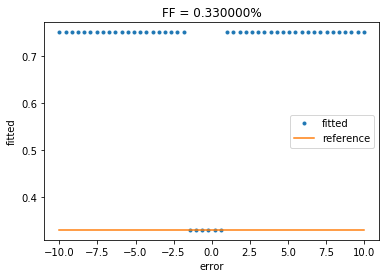

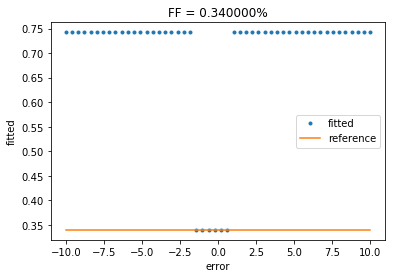

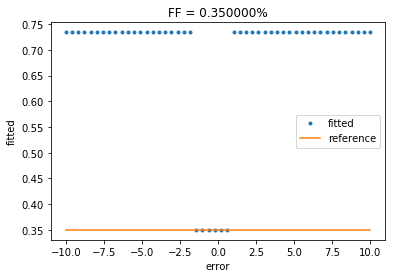

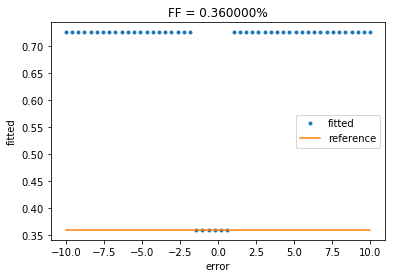

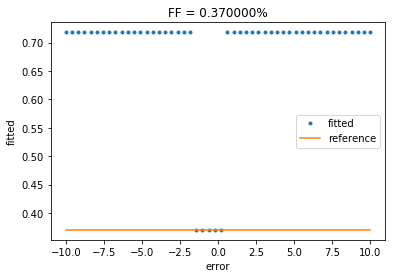

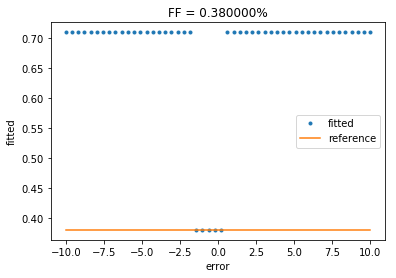

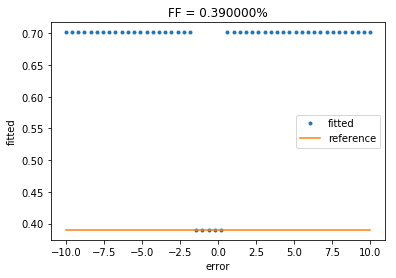

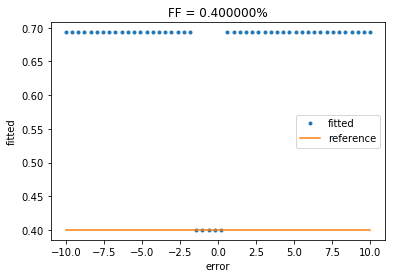

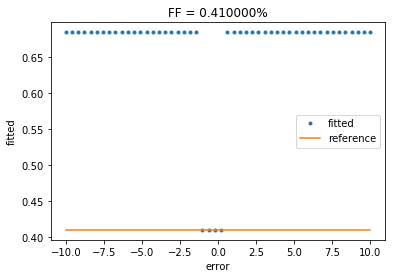

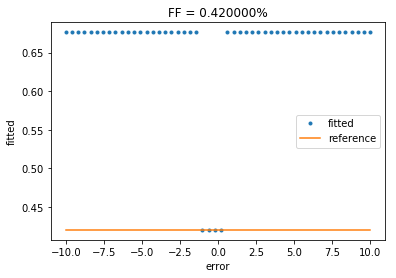

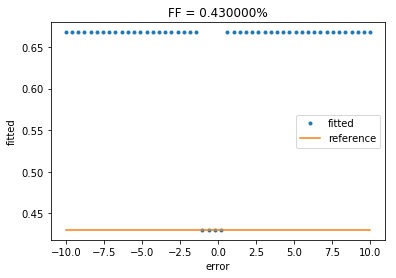

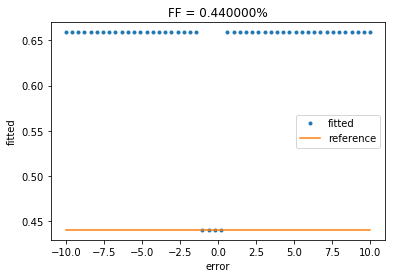

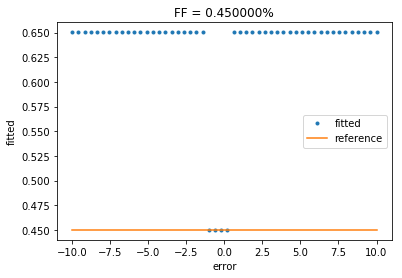

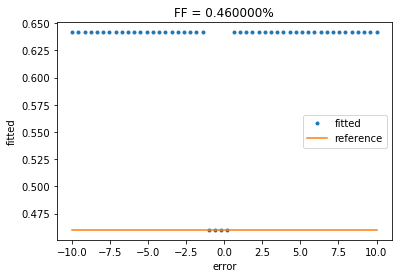

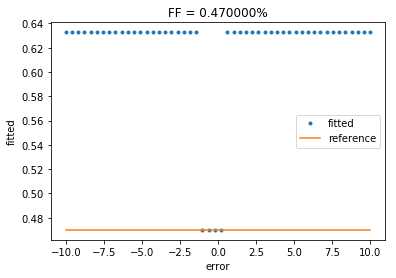

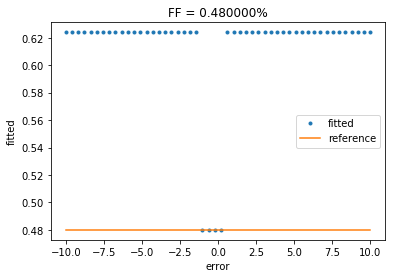

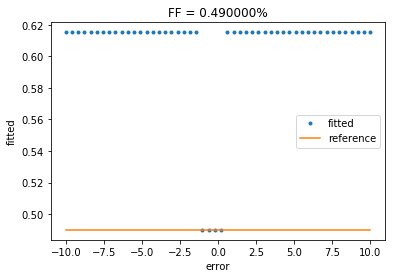

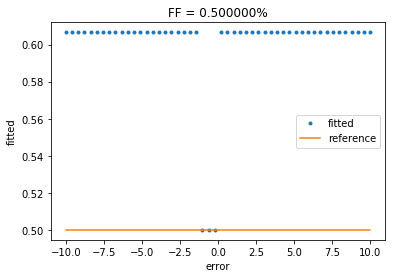

In [4]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.50)   # fat fraction
error = np.linspace(-10,10)    # erro para valores iniciais
fitted1 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    fitted1 = []
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [rho_fat+erro, rho_water] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1.append(calc_fatfrac(fitted_par))
    
    ref = np.zeros(np.size(fitted1))+n #original FF
    
    plt.figure()
    plt.title('FF = %f%%' % n)
    plt.xlabel('error')
    plt.ylabel('fitted')
    plt.plot(error, fitted1,'.', label='fitted')
    plt.plot(error, ref, label='reference')
    plt.legend()
    plt.show()

# Variando o valor inicial da agua

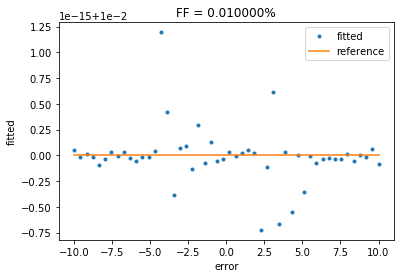

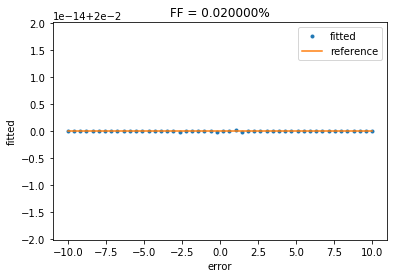

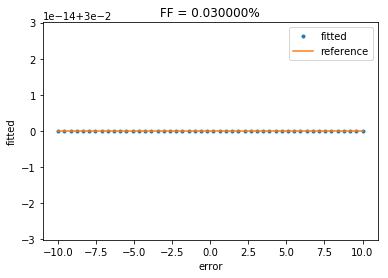

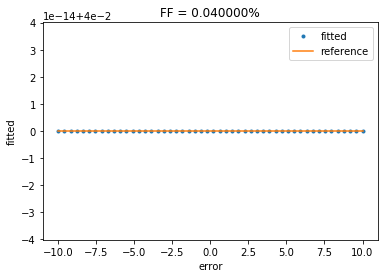

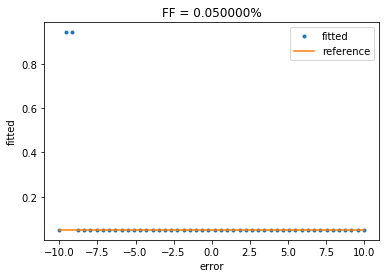

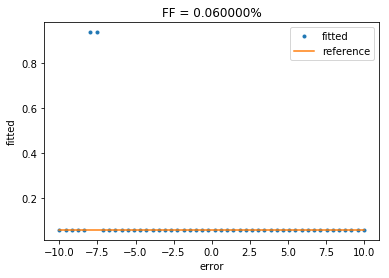

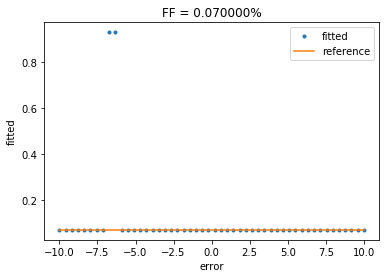

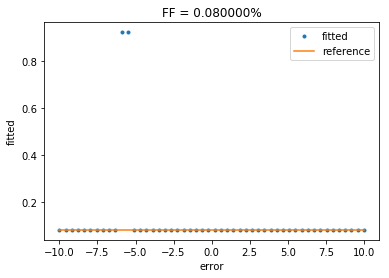

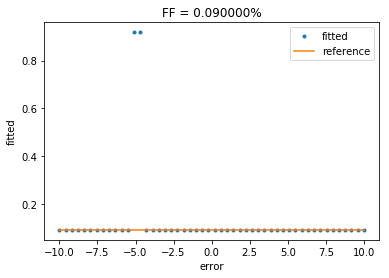

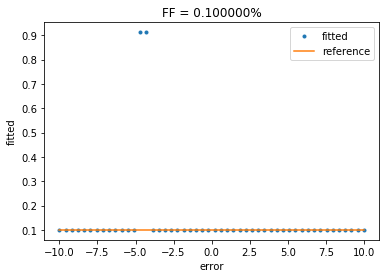

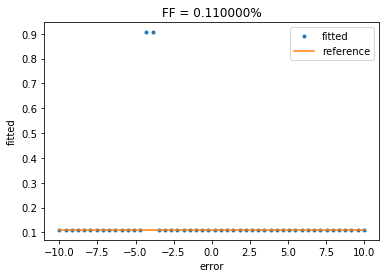

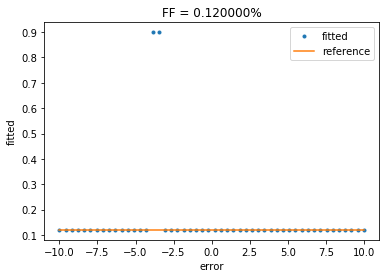

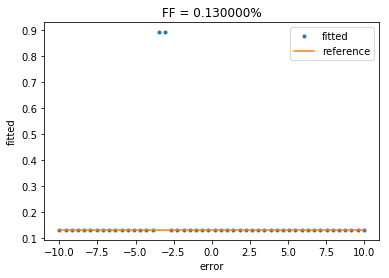

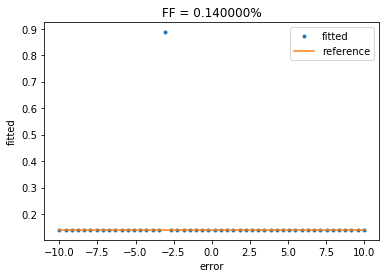

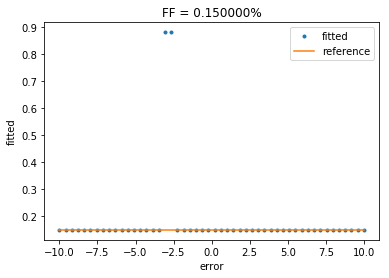

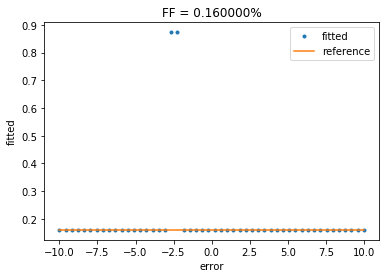

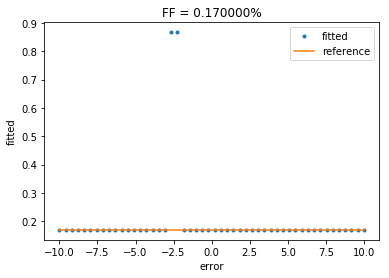

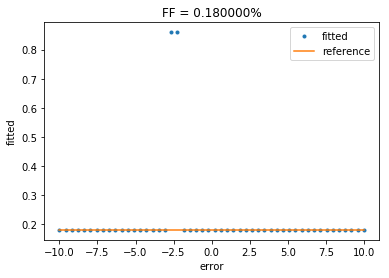

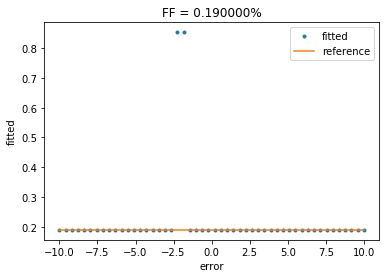

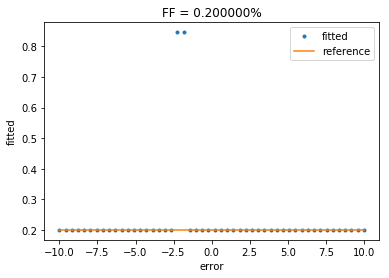

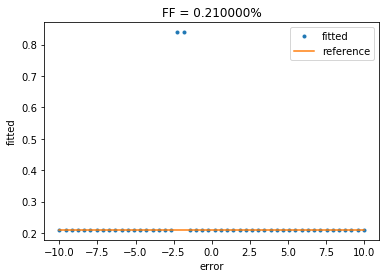

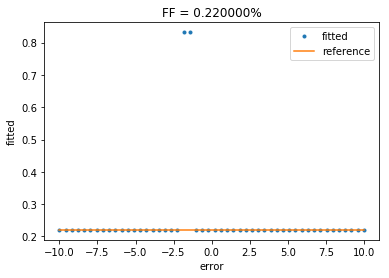

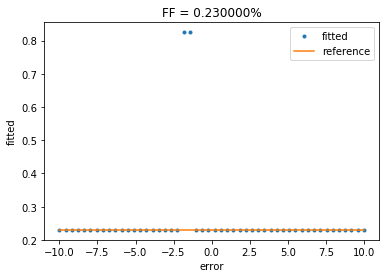

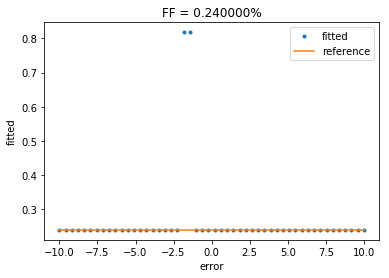

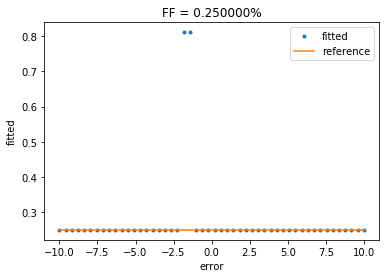

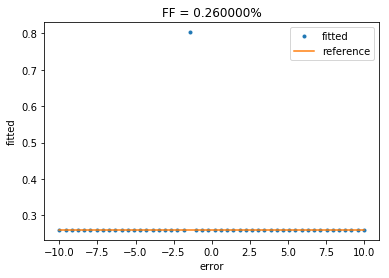

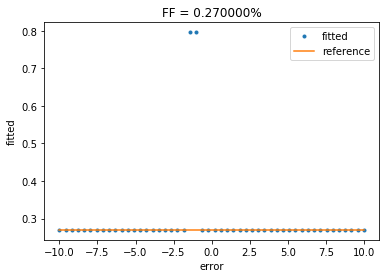

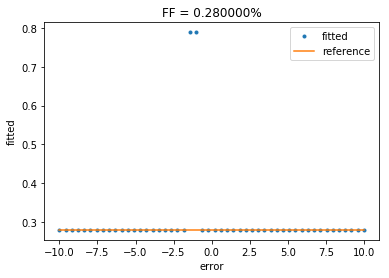

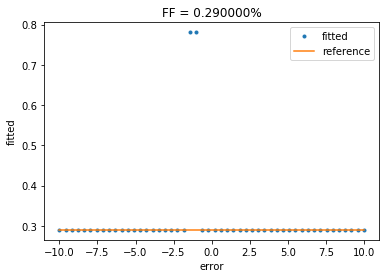

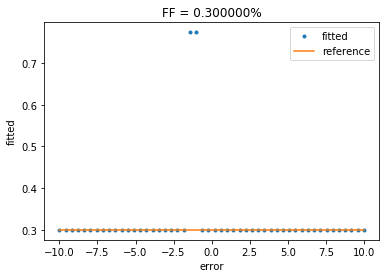

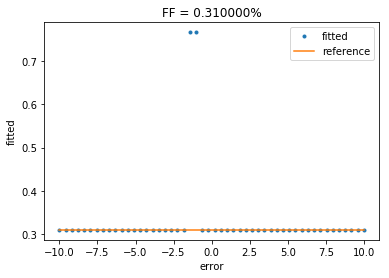

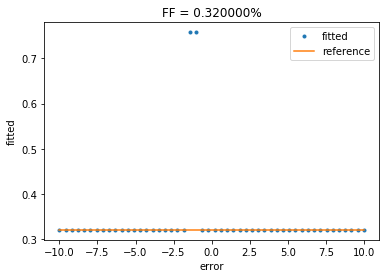

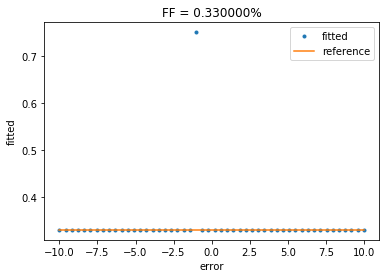

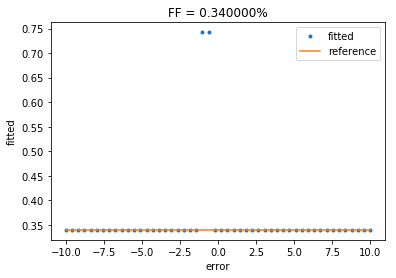

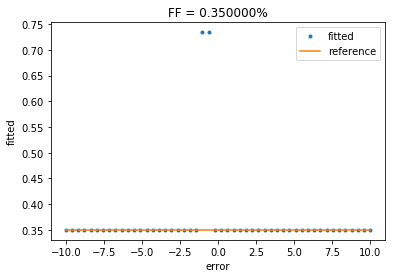

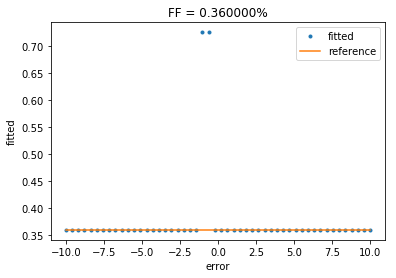

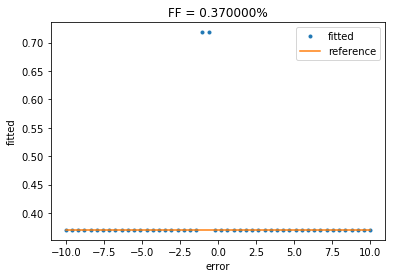

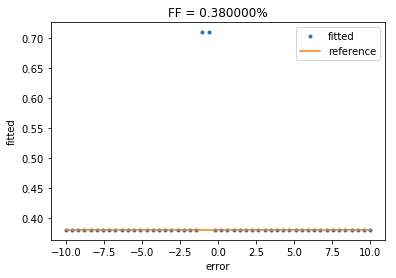

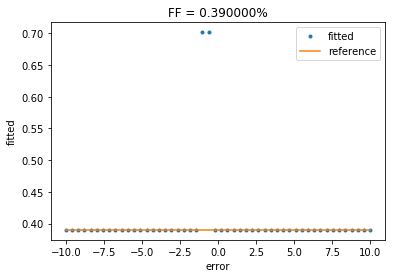

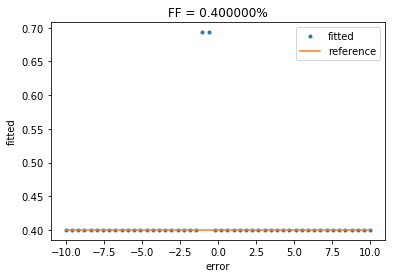

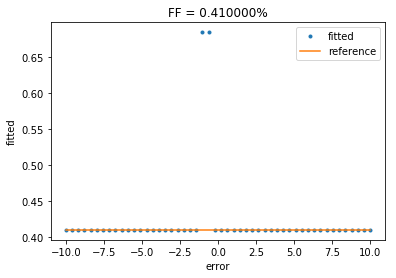

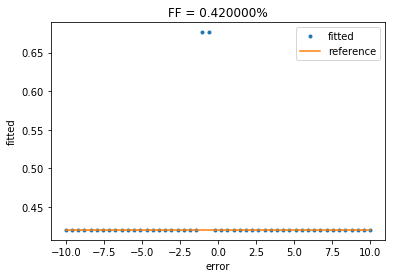

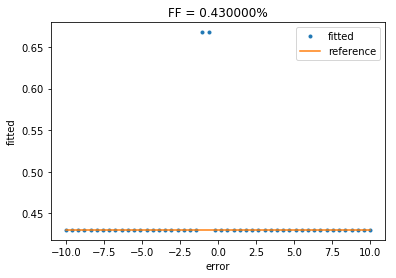

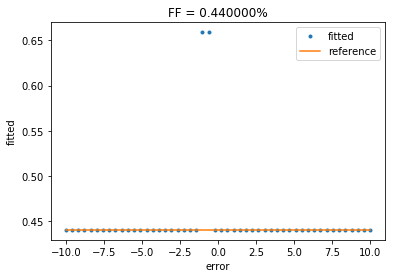

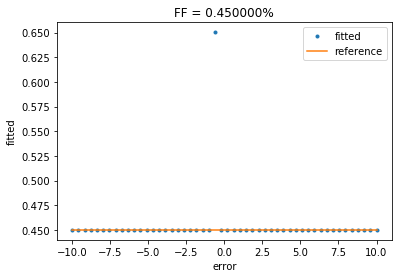

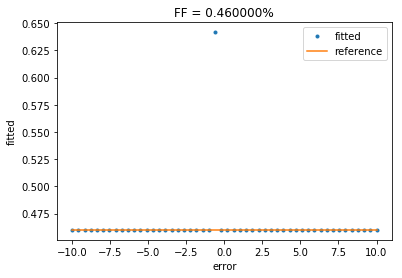

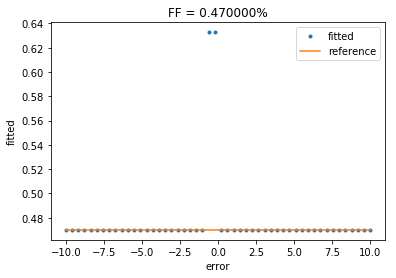

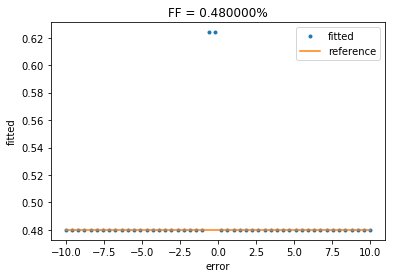

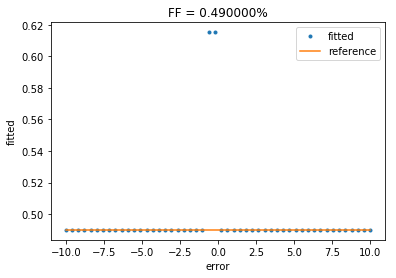

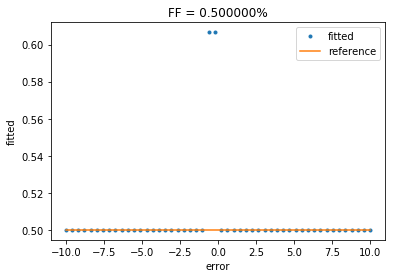

In [3]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.50)   # fat fraction
error = np.linspace(-10,10)    # erro para valores iniciais
fitted1 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    fitted1 = []
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [rho_fat, rho_water+erro] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1.append(calc_fatfrac(fitted_par))
    
    ref = np.zeros(np.size(fitted1))+n #original FF
    
    plt.figure()
    plt.title('FF = %f%%' % n)
    plt.xlabel('error')
    plt.ylabel('fitted')
    plt.plot(error, fitted1,'.', label='fitted')
    plt.plot(error, ref, label='reference')
    plt.legend()
    plt.show()
    

# Variando o valor inicial da agua e gordura

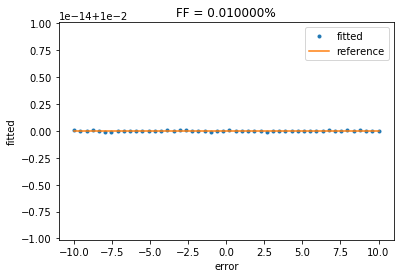

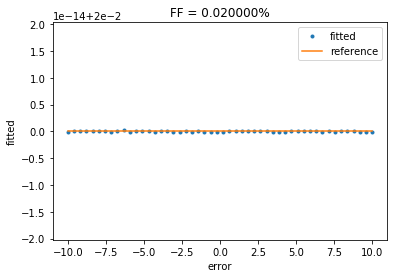

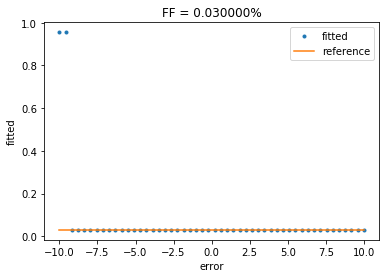

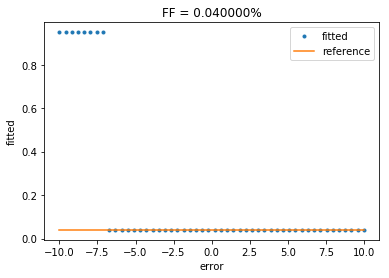

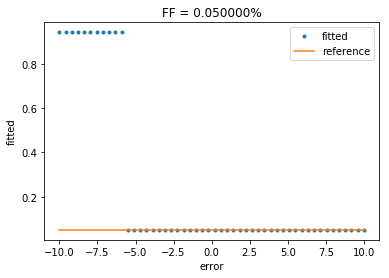

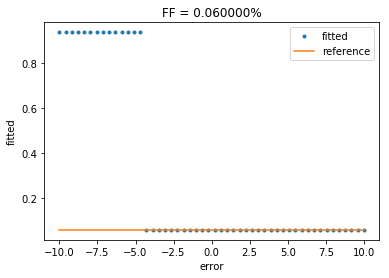

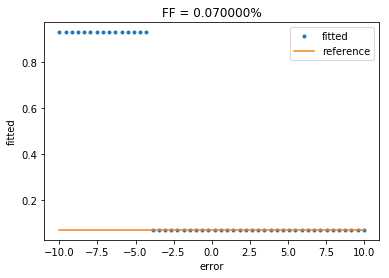

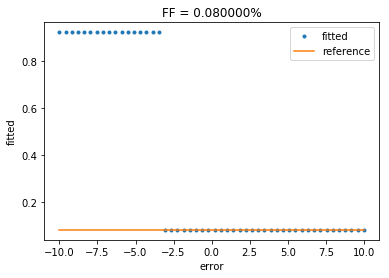

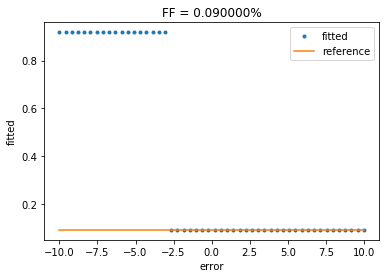

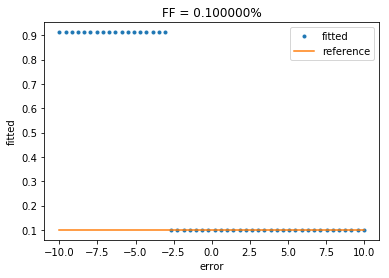

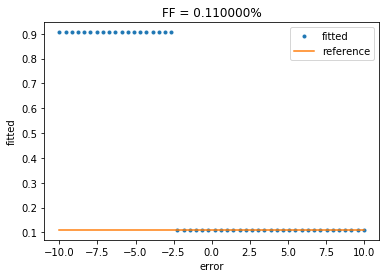

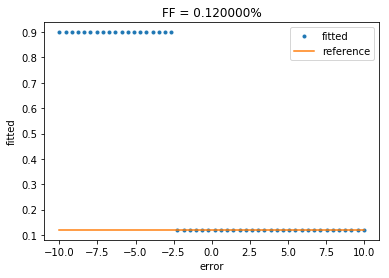

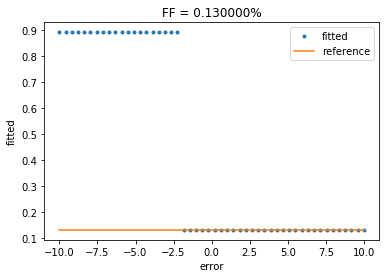

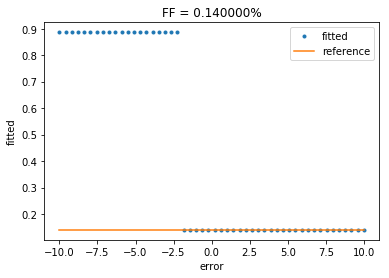

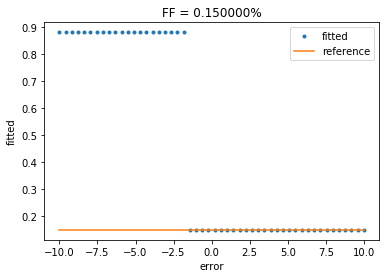

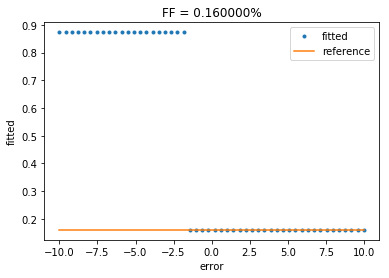

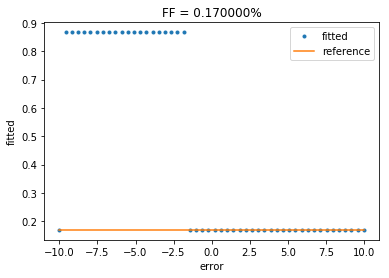

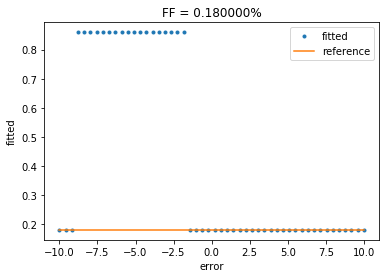

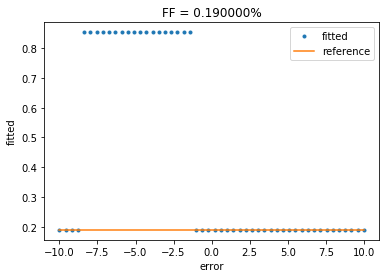

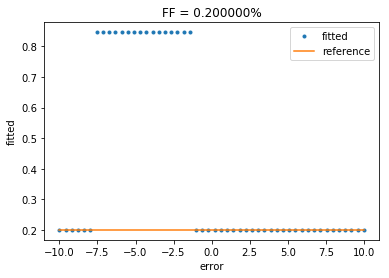

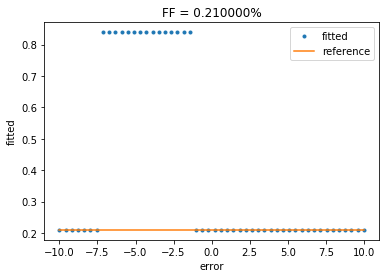

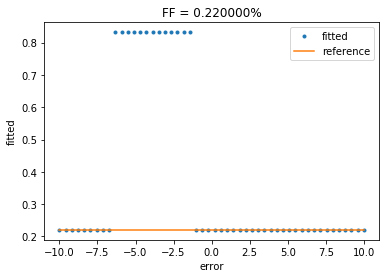

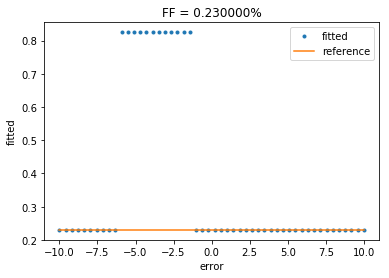

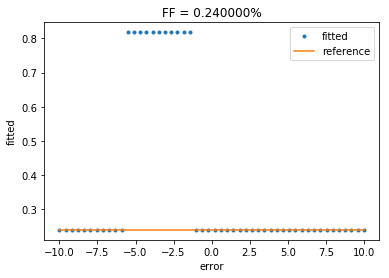

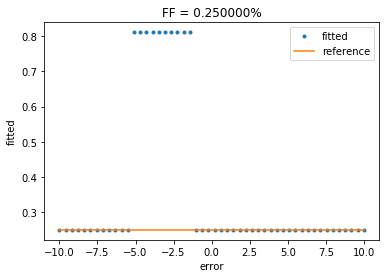

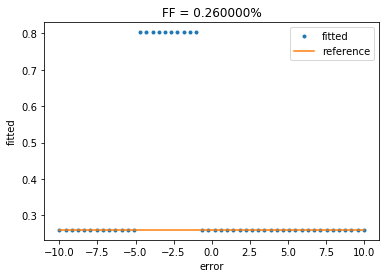

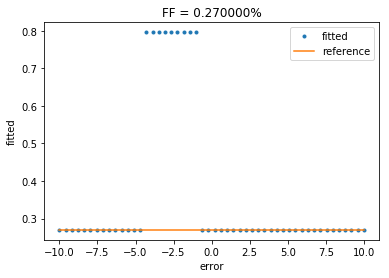

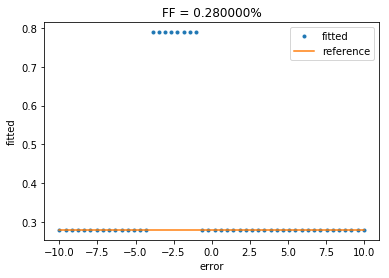

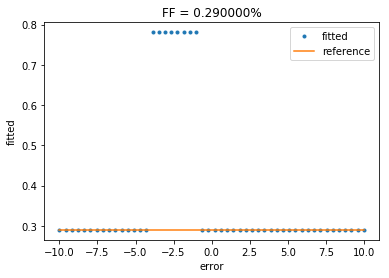

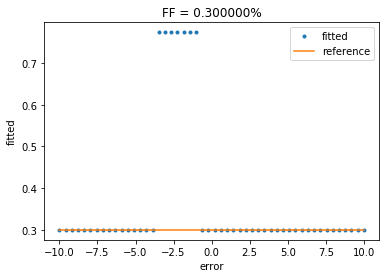

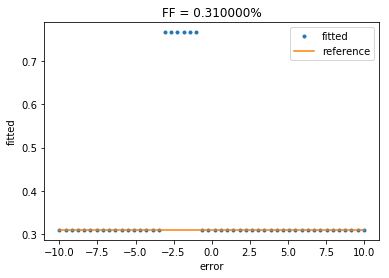

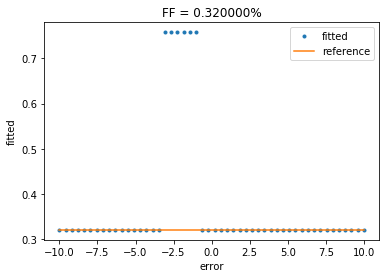

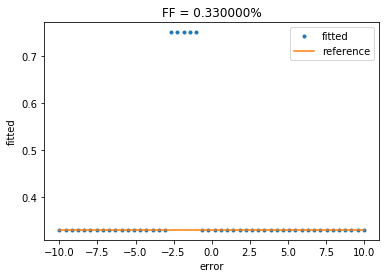

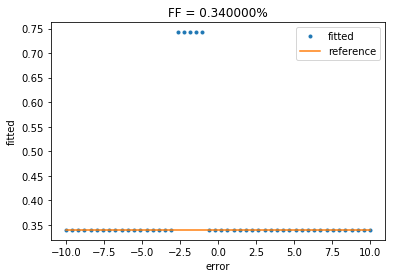

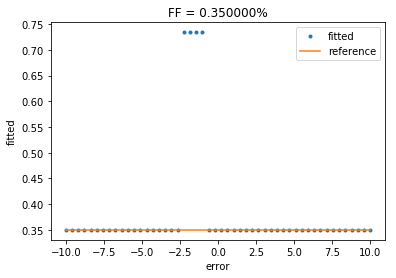

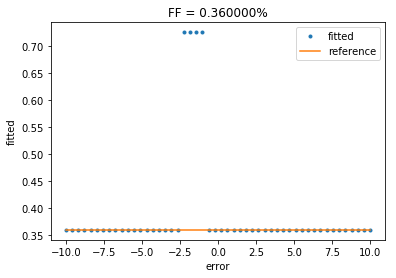

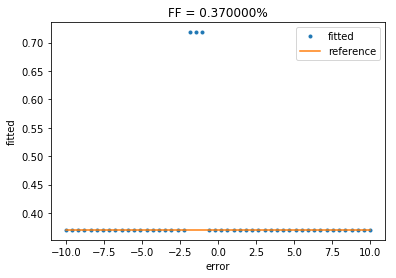

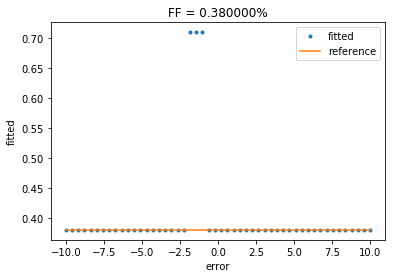

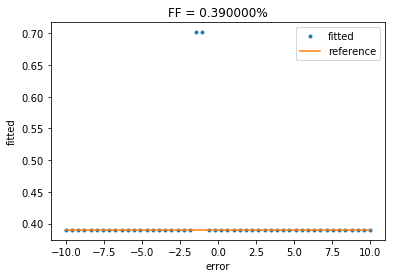

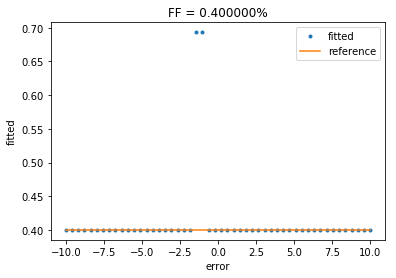

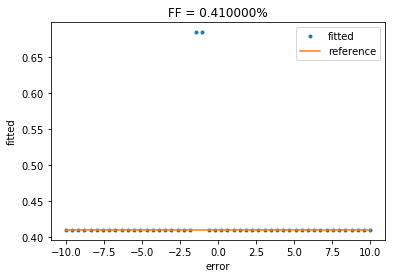

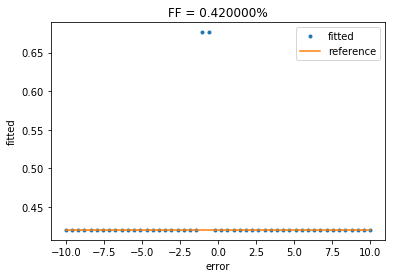

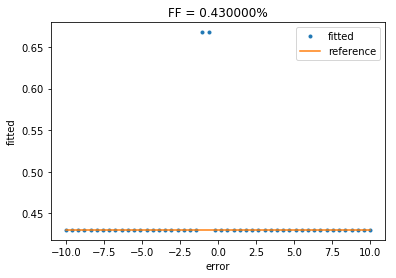

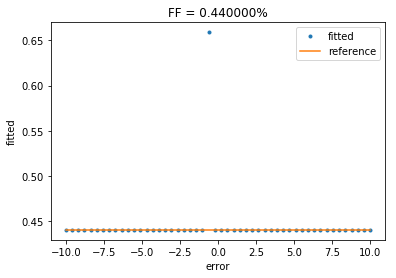

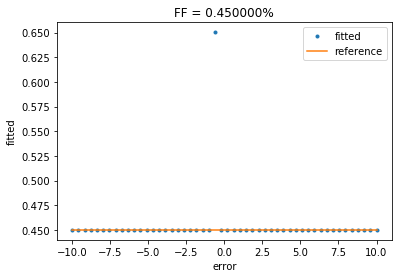

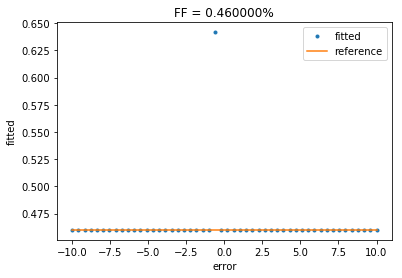

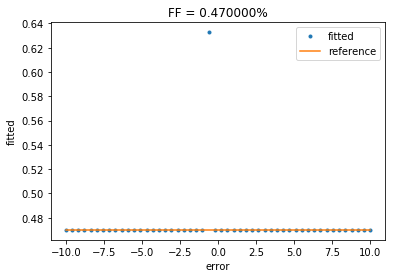

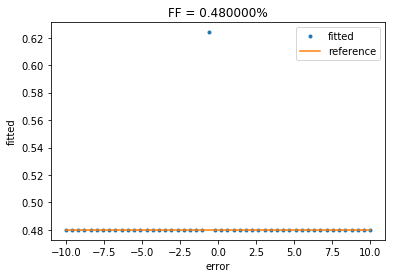

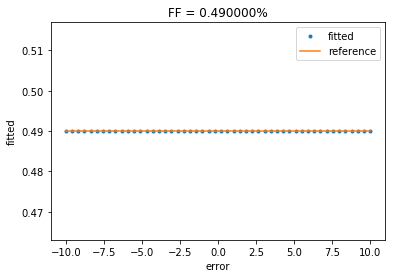

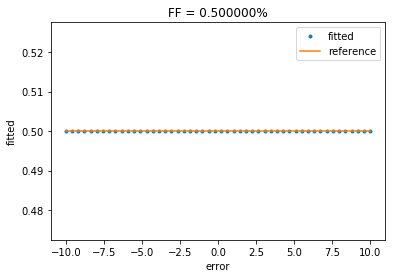

In [4]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.50)   # fat fraction
error = np.linspace(-10,10)    # erro para valores iniciais
fitted1 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    fitted1 = []
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [rho_fat+erro, rho_water+erro] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1.append(calc_fatfrac(fitted_par))
    
    ref = np.zeros(np.size(fitted1))+n #original FF
    
    plt.figure()
    plt.title('FF = %f%%' % n)
    plt.xlabel('error')
    plt.ylabel('fitted')
    plt.plot(error, fitted1,'.', label='fitted')
    plt.plot(error, ref, label='reference')
    plt.legend()
    plt.show()

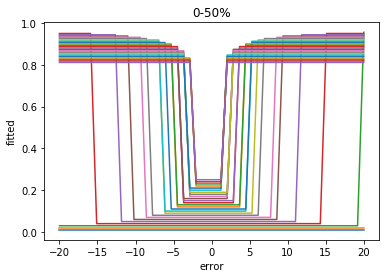

0.46
[ 0.64158452  0.64158452  0.64158452  0.64158452  0.64158452  0.64158452
  0.64158452  0.64158452  0.64158452  0.64158452  0.64158452  0.64158452
  0.64158452  0.64158452  0.64158452  0.64158452  0.64158452  0.64158452
  0.64158452  0.64158452  0.64158452  0.64158452  0.64158453  0.46        0.46
  0.64158453  0.64158453  0.64158452  0.64158452  0.64158452  0.64158452
  0.64158452  0.64158452  0.64158452  0.64158452  0.64158452  0.64158452
  0.64158452  0.64158452  0.64158452  0.64158452  0.64158452  0.64158452
  0.64158452  0.64158452  0.64158452  0.64158452  0.64158452  0.64158452
  0.64158452]


In [6]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.50)   # fat fraction
error = np.linspace(-20,20)    # erro para valores iniciais
fitted1 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [rho_fat+erro, rho_water] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1.append(calc_fatfrac(fitted_par))

# Cada linha do fitted1 é o parâmetro encontrado no curve_fit, cada coluna é um valor de erro
fitted1 = np.reshape(np.array(fitted1), (np.size(error), np.size(ff)))

plt.figure(1)
plt.xlabel('error')
plt.ylabel('fitted')
for i in range(int(np.size(fitted1[0])/2)):
    plt.title('0-50%')
    plt.plot(error, fitted1[i,:])
plt.savefig('fitted_error.png')
plt.show()

'''plt.figure(2)
plt.xlabel('error')
plt.ylabel('fitted')
for i in range(int(np.size(fitted1[0])/2)):
    plt.title('50-100%')
    plt.plot(error, fitted1[int((np.size(fitted1[0])/2)+i),:])
plt.show()'''

print(ff[45])
print(fitted1[45])

# testes a revisar

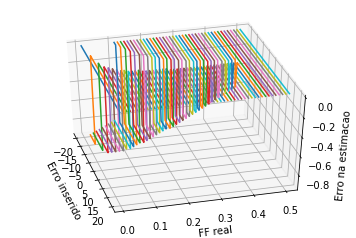

In [6]:
# preamble
from mpl_toolkits.mplot3d.axes3d import Axes3D
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
cs = ['r','g','b','y','r','g','b','y','r','g','b','y']

fat_fract = list(np.linspace(0.01,0.50))
for ff in fat_fract:    
    x = continuous_timeseries()

    fitted_parameter3 = []

    erro = list(np.linspace(-20,20))

    for n in erro:
        rho_fat, rho_water = set_rho(ff)
        xdata = discrete_timeseries(7)
        ydata = gen_GRE(xdata, rho_fat, rho_water)

        p0 = [rho_fat + n, rho_water + n]
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) # valores iniciais + random em 0.01
        fitted_parameter3.append(fitted_par)

    fitted3 = np.array([calc_fatfrac(x) for x in fitted_parameter3])
    
    # x axis
    X = erro

    # y axis
    Y = np.zeros(50)+ff

    # data - plotted against z axis
    Z = ff-fitted3

    # populate figure
    ax.plot(X, np.array(Y), Z)

ax.set_xlabel('Erro inserido')
ax.set_ylabel('FF real')
ax.set_zlabel('Erro na estimacao')
    # set initial view of plot
ax.view_init(elev=40., azim=345.)
plt.show()    


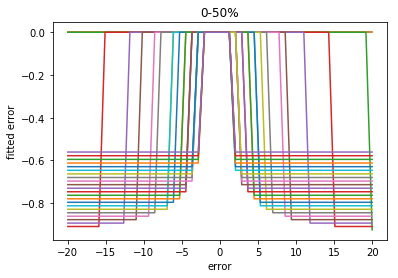

"plt.figure(2)\nplt.xlabel('error')\nplt.ylabel('fitted error')\nfor i in range(np.size(fitted1[0])/2):\n    plt.title('50-100%')\n    plt.plot(error, ff[i]-fitted1[(np.size(fitted1[0])/2)+i,:])\nplt.show()"

In [7]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.50)   # fat fraction
error = np.linspace(-20,20)    # erro para valores iniciais
fitted1 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [rho_fat+erro, rho_water] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1.append(calc_fatfrac(fitted_par))

# Cada linha do fitted1 é o parâmetro encontrado no curve_fit, cada coluna é um valor de erro
fitted1 = np.reshape(np.array(fitted1), (np.size(error), np.size(ff)))

plt.figure(1)
plt.xlabel('error')
plt.ylabel('fitted error')
for i in range(int(np.size(fitted1[0])/2)):
    plt.title('0-50%')
    plt.plot(error, ff[i]-fitted1[i,:])
plt.show()

'''plt.figure(2)
plt.xlabel('error')
plt.ylabel('fitted error')
for i in range(np.size(fitted1[0])/2):
    plt.title('50-100%')
    plt.plot(error, ff[i]-fitted1[(np.size(fitted1[0])/2)+i,:])
plt.show()'''

In [8]:
print(fitted1[3])
print(ff[3])

[ 0.94920385  0.94920385  0.94920386  0.94920385  0.94920386  0.94920385
  0.04        0.04        0.04        0.04        0.04        0.04        0.04
  0.04        0.04        0.04        0.04        0.04        0.04        0.04
  0.04        0.04        0.04        0.04        0.04        0.04        0.04
  0.04        0.04        0.04        0.04        0.04        0.04        0.04
  0.04        0.04        0.04        0.04        0.04        0.04        0.04
  0.04        0.04        0.94920386  0.94920386  0.94920386  0.94920386
  0.94920386  0.94920386  0.94920386]
0.04


[[ 0.01        0.01        0.01       ...,  0.01        0.01        0.01      ]
 [ 0.02        0.02        0.02       ...,  0.02        0.02        0.02      ]
 [ 0.03        0.03        0.03       ...,  0.03        0.03        0.95517036]
 ..., 
 [ 0.62394697  0.62394697  0.62394697 ...,  0.62394697  0.62394697
   0.62394697]
 [ 0.61520148  0.61520148  0.61520148 ...,  0.61520148  0.61520148
   0.61520148]
 [ 0.60662677  0.60662677  0.60662677 ...,  0.60662677  0.60662677
   0.60662677]]


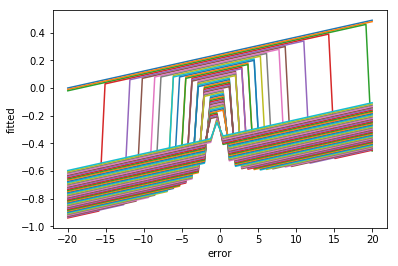

In [9]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.50)   # fat fraction
error = np.linspace(-20,20)    # erro para valores iniciais
fitted1 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [rho_fat+erro, rho_water] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1.append(calc_fatfrac(fitted_par))

# Cada linha do fitted1 é o parâmetro encontrado no curve_fit, cada coluna é um valor de erro
fitted1 = np.reshape(np.array(fitted1), (np.size(error), np.size(ff)))

print(fitted1)

plt.xlabel('error')
plt.ylabel('fitted')

for i in range(np.size(fitted1[0])):
    plt.plot(error, ff-fitted1[i,:])


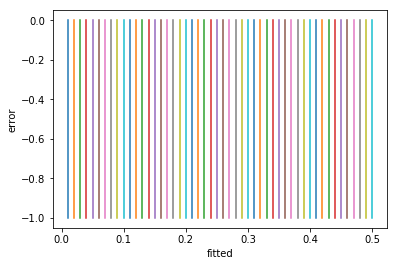

In [10]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.50)   # fat fraction
error = np.linspace(-1,0)    # erro para valores iniciais
fitted_0 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [rho_fat+erro, rho_water] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted_0.append(calc_fatfrac(fitted_par))

# Cada linha do fitted1 é o parâmetro encontrado no curve_fit, cada coluna é um valor de erro
fitted_0 = np.reshape(np.array(fitted_0), (np.size(error), np.size(ff)))

plt.xlabel('fitted')
plt.ylabel('error')
for i in range(np.size(fitted_0[0])):
    plt.plot(fitted_0[i,:],error)

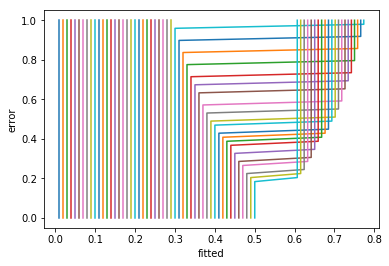

In [11]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.50)   # fat fraction
error = np.linspace(0,1)    # erro para valores iniciais
fitted_01 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [rho_fat+erro, rho_water] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted_01.append(calc_fatfrac(fitted_par))

# Cada linha do fitted1 é o parâmetro encontrado no curve_fit, cada coluna é um valor de erro
fitted_01 = np.reshape(np.array(fitted_01), (np.size(error), np.size(ff)))

plt.xlabel('fitted')
plt.ylabel('error')
for i in range(np.size(fitted_01[0])):
    plt.plot(fitted_01[i,:],error)

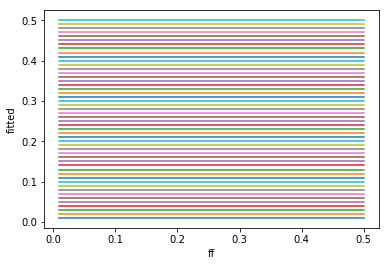

In [12]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.50)   # fat fraction
error = np.zeros(50)    # erro para valores iniciais
fitted_zeros = []                 # lista com parametros encontrados no fit
        
for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in error:
        p0 = [rho_fat+erro, rho_water] # FAT + ERROR
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted_zeros.append(calc_fatfrac(fitted_par))

# Cada linha do fitted1 é o parâmetro encontrado no curve_fit, cada coluna é um valor de erro
fitted_zeros = np.reshape(np.array(fitted_zeros), (np.size(error), np.size(ff)))

plt.xlabel('ff')
plt.ylabel('fitted')
for i in range(np.size(fitted_zeros[0])):
    plt.plot(ff, fitted_zeros[i,:])

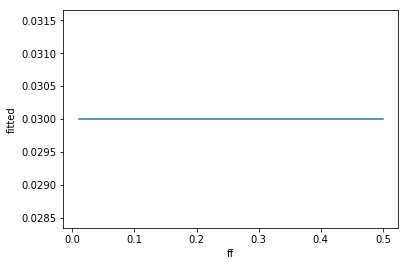

In [13]:
plt.plot(ff, fitted_zeros[2,:])
plt.xlabel('ff')
plt.ylabel('fitted')